<a href="https://colab.research.google.com/github/va24nsh/Major-Project/blob/main/MixerSENet_Houston.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MixerSENet — Hyperspectral Image Classification (Houston13)

This notebook implements the **MixerSENet** architecture from:  
> *"MixerSENet: A Lightweight Framework for Efficient Hyperspectral Image Classification"*  
> Alkhatib, Kumar Roy & Jamali — IEEE GRSL 2025  

**Notebook structure:**
1. Imports & Configuration
2. Utility Functions (data loading, PCA, patching, visualization)
3. FLOP Estimator
4. Model Architecture — SE Block
5. Model Architecture — Activation Block
6. **Model Architecture — Mixer Block** *(isolated for experimentation)*
7. Model Architecture — MixerSENet Assembly
8. Dataset Loading & Preprocessing (Houston13)
9. Train/Val/Test Split & Patch Extraction
10. Model Construction & Summary
11. Training
12. Evaluation (OA, AA, Kappa)
13. Classification Map Generation & Visualization
14. Save Results

---
## Cell 1 — Imports & Configuration
All third-party imports and user-configurable paths / hyperparameters are collected here so nothing else in the notebook needs editing for a standard run.

In [1]:
!pip install spectral
!pip install tensorflow

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpts
import spectral
import scipy.io as sio

from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import minmax_scale
from sklearn.metrics import cohen_kappa_score, accuracy_score, confusion_matrix
from tqdm import tqdm

import tensorflow as tf
from tensorflow import keras
from keras import layers
from tensorflow.keras.callbacks import ModelCheckpoint

# ────────────────────────── USER CONFIGURATION ──────────────────────────
# Path to the folder that contains the .mat dataset files.
# Change this to wherever your Houston13 dataset files are stored.
# DATASET_DIR = os.path.join(os.getcwd(), 'datasets')
DATASET_DIR = '/content/drive/MyDrive/datasets'

# Hyperparameters (matching the original paper defaults)
NUM_PCA_COMPONENTS = 15       # Number of PCA components for dimensionality reduction
WINDOW_SIZE        = 9        # Spatial patch size (window_size x window_size)
DEPTH              = 5        # Number of mixer blocks stacked
FILTERS            = 64       # Number of filters in each mixer / conv layer
EPOCHS             = 100      # Training epochs
BATCH_SIZE         = 64       # Training batch size
LEARNING_RATE      = 5e-4     # Initial Adam learning rate
VAL_SPLIT_RATIO    = 0.50     # Fraction of training samples used for validation
SE_RATIO           = 8        # Squeeze-and-Excitation reduction ratio
CHECKPOINT_PATH    = 'Houston_MixerSE.h5'  # Best-weights checkpoint filename

print('TensorFlow version:', tf.__version__)
print('Dataset directory :', DATASET_DIR)

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow version: 2.21.0
Dataset directory : /content/drive/MyDrive/datasets


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Cell 2 — Utility Functions
Core helpers ported verbatim from `utils.py`:  
- `get_img_indexes` — extract labelled pixel coordinates from a ground-truth map  
- `createImageCubes` — cut spatial patches around each pixel with zero-padding  
- `splitTrainTestSet` — stratified train/test split wrapper  
- `applyPCA` — dimensionality reduction + min-max normalisation  
- `predict_by_batching` — memory-safe batched inference  
- `get_class_map` — produce a full predicted classification map  
- `img_display` — plot RGB or class-coloured images  
- `display_history` — plot training/validation loss & accuracy curves

In [3]:
# ──────────────────────────────────────────────────────────────────────────
# get_img_indexes: returns pixel indices and 0-based labels from a 2-D
# ground-truth map.  When removeZeroindexes=True only labelled (non-zero)
# pixels are returned.
# ──────────────────────────────────────────────────────────────────────────
def get_img_indexes(class_map, removeZeroindexes=True):
    if removeZeroindexes:
        indices = np.argwhere(class_map != 0)
    else:
        indices = np.argwhere(class_map != None)
    labels = class_map[indices[:, 0], indices[:, 1]]
    indices = [tuple(idx) for idx in indices]
    return indices, np.array(labels.tolist()) - 1


# ──────────────────────────────────────────────────────────────────────────
# createImageCubes: extracts (windowSize x windowSize x bands) patches
# centred on each index from a zero-padded version of the image.
# ──────────────────────────────────────────────────────────────────────────
def createImageCubes(X, indices, windowSize):
    margin = windowSize // 2
    N, M, P = X.shape
    X_padded = np.zeros((N + 2 * margin, M + 2 * margin, P))
    x_offset = margin
    y_offset = margin
    X_padded[x_offset:N + x_offset, y_offset:M + y_offset, :] = X

    patches = []
    for idx in indices:
        i, j = idx
        i = i + margin
        j = j + margin
        i_min = i - margin
        i_max = i_min + windowSize
        j_min = j - margin
        j_max = j_min + windowSize
        patch = X_padded[i_min:i_max, j_min:j_max, :]
        patches.append(patch)
    return np.array(patches)


# ──────────────────────────────────────────────────────────────────────────
# splitTrainTestSet: thin wrapper around sklearn's stratified split.
# ──────────────────────────────────────────────────────────────────────────
def splitTrainTestSet(X, y, testRatio):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=testRatio, stratify=y
    )
    return X_train, X_test, y_train, y_test


# ──────────────────────────────────────────────────────────────────────────
# applyPCA: reduce spectral bands via PCA, optionally normalise to [0,1].
# ──────────────────────────────────────────────────────────────────────────
def applyPCA(X, numComponents=15, normalization=True):
    if numComponents == 0:
        newX = np.reshape(X, (-1, X.shape[2]))
    else:
        newX = np.reshape(X, (-1, X.shape[2]))
        pca = PCA(n_components=numComponents)
        newX = pca.fit_transform(newX)
    if normalization:
        newX = minmax_scale(newX, axis=1)
    newX = np.reshape(newX, (X.shape[0], X.shape[1], -1))
    return newX


# ──────────────────────────────────────────────────────────────────────────
# predict_by_batching: runs inference in chunks to avoid GPU OOM on the
# full test set.  Patches are created on-the-fly per batch.
# ──────────────────────────────────────────────────────────────────────────
def predict_by_batching(model, input_tensor_idx, batch_size, X, windowSize):
    num_samples = len(input_tensor_idx)
    k = 0
    predictions = []
    for i in tqdm(range(0, num_samples, batch_size), desc="Progress"):
        k += 1
        batch = createImageCubes(X, input_tensor_idx[i:i + batch_size], windowSize)
        batch_predictions = model.predict(batch, verbose=0)
        predictions.append(batch_predictions)
    Y_pred_test = np.concatenate(predictions, axis=0)
    return Y_pred_test


# ──────────────────────────────────────────────────────────────────────────
# get_class_map: predicts classes for *every* pixel (including background)
# and reshapes the result back into the original spatial dimensions.
# ──────────────────────────────────────────────────────────────────────────
def get_class_map(model, X, label, window_size):
    indexes, labels = get_img_indexes(label, removeZeroindexes=False)
    y_pred = predict_by_batching(model, indexes, 10000, X, window_size)
    y_pred = (np.argmax(y_pred, axis=1)).astype(np.uint8)
    Y_pred = np.reshape(y_pred, label.shape) + 1
    return Y_pred


# ──────────────────────────────────────────────────────────────────────────
# img_display: renders either an RGB composite or a class map using the
# SPy default colour palette.
# ──────────────────────────────────────────────────────────────────────────
def img_display(data=None, rgb_band=None, classes=None, class_name=None,
                title=None, figsize=(7, 7), palette=spectral.spy_colors):
    if data is not None:
        im_rgb = np.zeros_like(data[:, :, 0:3])
        im_rgb = data[:, :, rgb_band]
        im_rgb = im_rgb / (np.max(np.max(im_rgb, axis=1), axis=0)) * 255
        im_rgb = np.asarray(im_rgb, np.uint8)
        fig, rgbax = plt.subplots(figsize=figsize)
        rgbax.imshow(im_rgb)
        rgbax.set_title(title)
        rgbax.axis('off')
    elif classes is not None:
        rgb_class = np.zeros((classes.shape[0], classes.shape[1], 3))
        for i in np.unique(classes):
            rgb_class[classes == i] = palette[i]
        rgb_class = np.asarray(rgb_class, np.uint8)
        _, classax = plt.subplots(figsize=figsize)
        classax.imshow(rgb_class)
        classax.set_title(title)
        classax.axis('off')


# ──────────────────────────────────────────────────────────────────────────
# display_history: dual-panel plot of loss and accuracy, plus a second
# figure highlighting the best validation epoch.
# ──────────────────────────────────────────────────────────────────────────
def display_history(history):
    loss     = history.history['loss']
    val_loss = history.history['val_loss']
    acc      = history.history['accuracy']
    val_acc  = history.history['val_accuracy']
    epochs   = range(1, len(loss) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, 'y', label='Training loss')
    plt.plot(epochs, val_loss, 'r', label='Validation loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, acc, 'y', label='Training accuracy')
    plt.plot(epochs, val_acc, 'r', label='Validation accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.ylim(0, 1)
    plt.legend(); plt.grid(True)
    plt.tight_layout(); plt.show()

    # Second figure: best-epoch highlight
    val_acc    = history.history['val_accuracy']
    best_epoch = np.argmax(val_acc)
    best_val   = val_acc[best_epoch]

    plt.figure(figsize=(10, 4))
    plt.plot(history.history['accuracy'], 'y', label='Train Acc')
    plt.plot(val_acc, 'r', label='Val Acc')
    plt.axvline(best_epoch, color='k', linestyle='--', label=f'Best Epoch ({best_epoch+1})')
    plt.scatter(best_epoch, best_val, color='black')
    plt.text(best_epoch, best_val, f"{best_val:.2f}", fontsize=10, color='black', va='bottom')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

print('Utility functions defined.')

Utility functions defined.


---
## Cell 3 — FLOP Estimator
Layer-wise FLOP / MACC counter ported from `net_flops.py`.  
Supports Conv2D, DepthwiseConv2D, SeparableConv2D, Dense, pooling, BN, etc.

In [12]:
# ──────────────────────────────────────────────────────────────────────────
# net_flops: walks every layer in a Keras model and estimates FLOPs and
# multiply-accumulate operations.  Pass table=True for a per-layer breakdown.
#
# _get_shape: helper for Keras 2/3 compatibility — handles both
# .get_shape().as_list() (Keras 2) and plain .shape tuples (Keras 3).
# ──────────────────────────────────────────────────────────────────────────

def _get_shape(tensor_or_list, idx=None):
    """Extract shape[1:4] as a Python list from a Keras tensor.
    Handles Keras 2 (.get_shape().as_list()) and Keras 3 (.shape is a tuple).
    If idx is given, index into the list/tuple first (for multi-input layers)."""
    if idx is not None:
        t = tensor_or_list[idx]
    elif isinstance(tensor_or_list, (list, tuple)):
        t = tensor_or_list[0]
    else:
        t = tensor_or_list

    if hasattr(t, 'get_shape'):
        return t.get_shape().as_list()
    elif hasattr(t, 'shape'):
        return list(t.shape)
    return []

def net_flops(model, table=False):
    if table:
        print('%25s | %16s | %16s | %16s | %16s | %6s | %6s' % (
            'Layer Name', 'Input Shape', 'Output Shape', 'Kernel Size',
            'Filters', 'Strides', 'FLOPS'))
        print('-' * 170)

    t_flops = 0
    t_macc  = 0

    for l in model.layers:
        o_shape, i_shape, strides, ks, filters = (
            ['', '', ''], ['', '', ''], [1, 1], [0, 0], [0, 0]
        )
        flops = 0
        macc  = 0
        name  = l.name
        factor = 1
        out_vec = 1

        if 'InputLayer' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            o_shape = i_shape

        if 'Reshape' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]

        if 'Add' in str(l) or 'Maximum' in str(l) or 'Concatenate' in str(l):
            i_shape = _get_shape(l.input[0])[1:4] + [len(l.input)]
            o_shape = _get_shape(l.output)[1:4]
            flops   = (len(l.input) - 1) * i_shape[0] * i_shape[1] * i_shape[2]

        if 'Average' in str(l) and 'pool' not in str(l):
            i_shape = _get_shape(l.input[0])[1:4] + [len(l.input)]
            o_shape = _get_shape(l.output)[1:4]
            flops   = len(l.input) * i_shape[0] * i_shape[1] * i_shape[2]

        if 'BatchNormalization' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]
            bflops  = 1
            for i in range(len(i_shape)):
                if i_shape[i] is not None:
                    bflops *= i_shape[i]
            flops /= factor

        if 'Activation' in str(l) or 'activation' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]
            bflops  = 1
            for i in range(len(i_shape)):
                if i_shape[i] is not None:
                    bflops *= i_shape[i]
            flops /= factor

        if 'pool' in str(l) and 'Global' not in str(l):
            i_shape = _get_shape(l.input)[1:4]
            strides = l.strides
            ks      = l.pool_size
            flops   = ((i_shape[0] / strides[0]) *
                       (i_shape[1] / strides[1]) *
                       (ks[0] * ks[1] * i_shape[2]))

        if 'Flatten' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            flops   = 1
            out_vec = 1
            for i in range(len(i_shape)):
                if i_shape[i] is not None:
                    flops   *= i_shape[i]
                    out_vec *= i_shape[i]
            o_shape = flops
            flops   = 0

        if 'Dense' in str(l):
            i_shapes = _get_shape(l.input)
            i_shape = i_shapes[-1] if len(i_shapes) > 0 else out_vec
            o_shapes = _get_shape(l.output)
            o_shape = o_shapes[-1] if len(o_shapes) > 0 else 1
            flops   = 2 * (o_shape * i_shape)
            macc    = flops / 2

        if 'Padding' in str(l):
            flops = 0

        if 'Global' in str(l):
            i_shape = _get_shape(l.input)[1:4]
            flops   = i_shape[0] * i_shape[1] * i_shape[2]
            o_shape = [_get_shape(l.output)[1:4], 1, 1]
            out_vec = o_shape[0][-1] if len(o_shape[0]) > 0 else 1

        if ('Conv2D ' in str(l) and 'DepthwiseConv2D' not in str(l)
                and 'SeparableConv2D' not in str(l)):
            strides = l.strides
            ks      = l.kernel_size
            filters = l.filters
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]
            if filters is None:
                filters = i_shape[2]
            flops = 2 * ((filters * ks[0] * ks[1] * i_shape[2]) *
                         ((i_shape[0] / strides[0]) * (i_shape[1] / strides[1])))
            macc  = flops / 2

        if ('Conv2D ' in str(l) and 'DepthwiseConv2D' in str(l)
                and 'SeparableConv2D' not in str(l)):
            strides = l.strides
            ks      = l.kernel_size
            filters = l.filters
            i_shape = _get_shape(l.input)[1:4]
            o_shape = _get_shape(l.output)[1:4]
            if filters is None:
                filters = i_shape[2]
            flops = 2 * ((ks[0] * ks[1] * i_shape[2]) *
                         ((i_shape[0] / strides[0]) * (i_shape[1] / strides[1])))
            macc  = flops / 2

        t_macc  += macc
        t_flops += flops

        if table:
            print('%25s | %16s | %16s | %16s | %16s | %6s | %5.4f' % (
                name, str(i_shape), str(o_shape), str(ks), str(filters),
                str(strides), flops))

    t_flops = t_flops / factor
    print('\nTotal FLOPS:', int(t_flops))
    print('\nTotal MACCs:', int(t_macc))
    return

print('FLOP estimator defined.')

FLOP estimator defined.


---
## Cell 4 — SE (Squeeze-and-Excitation) Block
Channel-attention mechanism: Global Average Pool → Dense (squeeze) → Dense (excite) → element-wise multiply.  
Reduction ratio is controlled by `se_ratio` (default 8).

In [5]:
# ──────────────────────────────────────────────────────────────────────────
# SE: Squeeze-and-Excitation block.  Learns per-channel importance weights
# via a bottleneck (squeeze → excite) and re-scales the input channels.
# ──────────────────────────────────────────────────────────────────────────
def SE(xin, se_ratio=SE_RATIO):
    # Global Average Pooling along spatial dimensions
    xin_gap = layers.GlobalAveragePooling2D()(xin)

    # Squeeze path — reduce channel dimension
    sqz = layers.Dense(int(xin.shape[-1]) // se_ratio, activation='relu')(xin_gap)

    # Excitation path — restore channel dimension with sigmoid gating
    excite = layers.Dense(int(xin.shape[-1]), activation='sigmoid')(sqz)

    # Scale the original input by the excitation weights
    out = layers.multiply([xin, layers.Reshape((1, 1, int(xin.shape[-1])))(excite)])
    return out

print('SE block defined.')

SE block defined.


---
## Cell 5 — Activation Block
Simple helper: **GELU activation → Batch Normalisation**.  
Used after every convolution in the mixer and stem.

In [6]:
# ──────────────────────────────────────────────────────────────────────────
# activation_block: GELU non-linearity followed by BatchNorm.
# ──────────────────────────────────────────────────────────────────────────
def activation_block(x):
    x = layers.Activation("gelu")(x)
    return layers.BatchNormalization()(x)

print('Activation block defined.')

Activation block defined.


---
## Cell 6 — Mixer Block ⚡ (ISOLATED — modify freely)
This is the core mixing mechanism of MixerSENet.  

**Current design (from the paper):**
1. Three parallel **DepthwiseConv2D** branches with kernel sizes 3×3, 5×5, 7×7  
2. Their outputs are summed with the residual  
3. A **pointwise Conv2D** (1×1) projects to `filters` channels  
4. GELU + BatchNorm  
5. Final residual addition  

> **This cell is intentionally isolated.**  
> You can freely modify the mixing strategy here (e.g., replace with Conv3D, change kernel sizes, add attention, etc.) without touching any other cell.

In [7]:
# ══════════════════════════════════════════════════════════════════════════
# ██  MIXER BLOCK — Freely editable / swappable  ██
# ══════════════════════════════════════════════════════════════════════════
#
# Interface contract (do NOT change the signature):
#   Input:  x       — 4-D tensor (batch, H, W, C)  where C == filters
#           filters — int, number of output channels (must match input C)
#           kernel_size — int (unused in current design but kept for API)
#   Output: 4-D tensor of the same shape as x
#
# Everything INSIDE this function can be changed without affecting the
# rest of the architecture.
# ══════════════════════════════════════════════════════════════════════════

def mixer_block(x, filters: int, kernel_size: int):
    # Save input for the two residual connections
    residuals = x

    # --- Multi-scale depthwise convolutions (spatial mixing) ---
    pos_emb1 = layers.DepthwiseConv2D(kernel_size=3, padding="same")(x)
    pos_emb2 = layers.DepthwiseConv2D(kernel_size=5, padding="same")(x)
    pos_emb3 = layers.DepthwiseConv2D(kernel_size=7, padding="same")(x)

    # Sum all branches with the residual
    x = keras.layers.Add()([residuals, pos_emb1, pos_emb2, pos_emb3])

    # --- Pointwise convolution (channel mixing) ---
    x = layers.Conv2D(filters, kernel_size=1)(x)
    x = activation_block(x)

    # Final residual addition
    x = layers.Add()([x, residuals])

    return x

print('Mixer block defined (isolated).')

Mixer block defined (isolated).


---
## Cell 7 — MixerSENet Model Assembly
Builds the full model:  
Input → 1×1 Conv (stem) → [Mixer Block × depth] → SE → Global Avg Pool → Dense (softmax)  
Compiled with Adam + categorical cross-entropy.

In [8]:
# ──────────────────────────────────────────────────────────────────────────
# MixerSENet: assembles the full classification model.
#   - 1x1 Conv stem to project input bands to 'filters' channels
#   - 'depth' repeated mixer_block calls
#   - SE channel-attention
#   - Global average pooling + softmax classifier
# ──────────────────────────────────────────────────────────────────────────
def MixerSENet(img_list, NumClasses, depth, filters):
    inputs = keras.Input(img_list.shape[1:])

    # Stem: project spectral channels to a fixed filter count
    x = layers.Conv2D(filters, kernel_size=1, strides=1)(inputs)
    x = activation_block(x)

    # Stack mixer blocks
    for ii in range(depth):
        x = mixer_block(x, filters, 3)

    # Channel attention
    x = SE(x)

    # Classification head
    x = layers.GlobalAvgPool2D()(x)
    logits = layers.Dense(NumClasses, activation="softmax")(x)

    model = keras.Model(inputs=[inputs], outputs=logits)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print('MixerSENet builder defined.')

MixerSENet builder defined.


---
## Cell 8 — Load Houston13 Dataset & PCA
Loads the three .mat files (HSI cube, train labels, test labels), applies PCA for dimensionality reduction, and displays the ground-truth map.

HSI cube shape after PCA: (349, 1905, 15)
Number of classes: 15


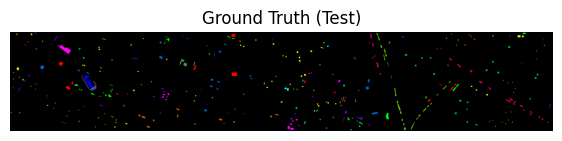

In [9]:
# ──────────────────────────────────────────────────────────────────────────
# Load the Houston 2013 dataset from .mat files.
# X            — raw hyperspectral cube  (H x W x Bands)
# Tr_labels    — training ground-truth   (H x W), 0 = unlabelled
# Te_labels    — testing ground-truth    (H x W), 0 = unlabelled
# gt           — combined ground-truth   (union of train + test labels)
# ──────────────────────────────────────────────────────────────────────────
X         = sio.loadmat(os.path.join(DATASET_DIR, 'Houston13_HSI.mat'))['data_HS_HR']
Tr_labels = sio.loadmat(os.path.join(DATASET_DIR, 'Houston_TrainImage.mat'))['TrainImage']
Te_labels = sio.loadmat(os.path.join(DATASET_DIR, 'Houston_TestImage.mat'))['TestImage']

gt        = Tr_labels + Te_labels
NUM_CLASS = int(Te_labels.max())

class_name = [
    'Healthy Grass', 'Stressed Grass', 'Synthetic Grass',
    'Tree', 'Soil', 'Water', 'Residential', 'Commercial',
    'Road', 'Highway', 'Railway', 'Parking Lot1',
    'Parking Lot2', 'Tennis Court', 'Running Track'
]

_, labels = get_img_indexes(gt, removeZeroindexes=True)

# Display the test ground-truth map
img_display(classes=Te_labels, title='Ground Truth (Test)', class_name=class_name)

# Apply PCA for dimensionality reduction
data = applyPCA(X, numComponents=NUM_PCA_COMPONENTS, normalization=True)

print(f'HSI cube shape after PCA: {data.shape}')
print(f'Number of classes: {NUM_CLASS}')

---
## Cell 9 — Train / Val / Test Split & Patch Extraction
Houston13 comes with predefined train/test splits.  
The training set is further halved into train + validation.  
Spatial patches of size `WINDOW_SIZE × WINDOW_SIZE` are extracted around each labelled pixel.

In [10]:
# ──────────────────────────────────────────────────────────────────────────
# Extract train / test indices from the predefined label maps, then
# split training into train + validation.
# ──────────────────────────────────────────────────────────────────────────
X_train_idx, y_train = get_img_indexes(Tr_labels, removeZeroindexes=True)
X_test_idx,  y_test  = get_img_indexes(Te_labels, removeZeroindexes=True)

num_samples_overall = len(X_train_idx) + len(X_test_idx)

X_train_idx, X_val_idx, y_train, y_val = splitTrainTestSet(
    X_train_idx, y_train, testRatio=VAL_SPLIT_RATIO
)

print("Training   Percentage =", format(100 * len(X_train_idx) / num_samples_overall, ".2f"), '%')
print("Validation Percentage =", format(100 * len(X_val_idx)   / num_samples_overall, ".2f"), '%')
print("Testing    Percentage =", format(100 * len(X_test_idx)  / num_samples_overall, ".2f"), '%')

# Per-class sample report
sample_report = f"{'class': ^25}{'train_num':^10}{'val_num': ^10}{'test_num': ^10}{'total': ^10}\n"
for i in np.unique(gt):
    if i == 0:
        continue
    sample_report += (f"{class_name[i-1]: ^25}"
                      f"{(y_train==i-1).sum(): ^10}"
                      f"{(y_val==i-1).sum(): ^10}"
                      f"{(y_test==i-1).sum(): ^10}"
                      f"{(gt==i).sum(): ^10}\n")
sample_report += (f"{'total': ^25}"
                  f"{len(y_train-1): ^10}"
                  f"{len(y_val): ^10}"
                  f"{len(y_test): ^10}"
                  f"{len(labels): ^10}")
print(sample_report)

# ──────────────────────────────────────────────────────────────────────────
# Create spatial patches and one-hot encode labels.
# ──────────────────────────────────────────────────────────────────────────
X_train = createImageCubes(data, X_train_idx, WINDOW_SIZE)
y_train = keras.utils.to_categorical(y_train)

X_val = createImageCubes(data, X_val_idx, WINDOW_SIZE)
y_val = keras.utils.to_categorical(y_val)

print(f'\nX_train shape: {X_train.shape}  |  y_train shape: {y_train.shape}')
print(f'X_val   shape: {X_val.shape}  |  y_val   shape: {y_val.shape}')

Training   Percentage = 9.42 %
Validation Percentage = 9.42 %
Testing    Percentage = 81.16 %
          class          train_num  val_num   test_num   total   
      Healthy Grass          99        99       1053      1251   
     Stressed Grass          95        95       1064      1254   
     Synthetic Grass         96        96       505       697    
          Tree               94        94       1056      1244   
          Soil               93        93       1056      1242   
          Water              91        91       143       325    
       Residential           98        98       1072      1268   
       Commercial            95        96       1053      1244   
          Road               97        96       1059      1252   
         Highway             96        95       1036      1227   
         Railway             90        91       1054      1235   
      Parking Lot1           96        96       1041      1233   
      Parking Lot2           92        92       

---
## Cell 10 — Build Model & Print Summary / FLOPs
Instantiates MixerSENet with the configured hyperparameters and prints the layer summary plus estimated FLOPs.

In [13]:
# ──────────────────────────────────────────────────────────────────────────
# Build the MixerSENet model and inspect it.
# ──────────────────────────────────────────────────────────────────────────
try:
    model = MixerSENet(
        img_list  = X_train,
        NumClasses = NUM_CLASS,
        depth     = DEPTH,
        filters   = FILTERS
    )
    model.summary()
    print()
    net_flops(model)
except Exception as e:
    import traceback
    traceback.print_exc()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 9, 9, 15)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 9, 9, 64)  │      1,024 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 9, 9, 64)  │          0 │ conv2d_6[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 9, 9, 64)  │        256 │ activation_6[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_15 │ (None, 9, 9, 64)  │        640 │ batch_normalizat… │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_16 │ (None, 9, 9, 64)  │      1,664 │ batch_normalizat… │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_17 │ (None, 9, 9, 64)  │      3,200 │ batch_normalizat… │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 9, 9, 64)  │          0 │ batch_normalizat… │
│                     │                   │            │ depthwise_conv2d… │
│                     │                   │            │ depthwise_conv2d… │
│                     │                   │            │ depthwise_conv2d… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 9, 9, 64)  │      4,160 │ add_10[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 9, 9, 64)  │          0 │ conv2d_7[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 9, 9, 64)  │        256 │ activation_7[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, 9, 9, 64)  │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_18 │ (None, 9, 9, 64)  │        640 │ add_11[0][0]      │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_19 │ (None, 9, 9, 64)  │      1,664 │ add_11[0][0]      │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_20 │ (None, 9, 9, 64)  │      3,200 │ add_11[0][0]      │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 9, 9, 64)  │          0 │ add_11[0][0],     │
│                     │                   │            │ depthwise_conv2d… │
│                     │                   │            │ depthwise_conv2d… │
│                     │                   │            │ depthwise_conv2d

 Total params: 52,951 (206.84 KB)

 Trainable params: 52,183 (203.84 KB)

 Non-trainable params: 768 (3.00 KB)

Traceback (most recent call last):
  File "/tmp/ipykernel_10218/1244935528.py", line 13, in <cell line: 0>
    net_flops(model)
    ~~~~~~~~~^^^^^^^
  File "/tmp/ipykernel_10218/2663386791.py", line 47, in net_flops
    i_shape = _get_shape(l.input)[1:4]
              ~~~~~~~~~~^^^^^^^^^
  File "/tmp/ipykernel_10218/2663386791.py", line 16, in _get_shape
    t = tensor_or_list[0]
        ~~~~~~~~~~~~~~^^^
IndexError: list index out of range


---
## Cell 11 — Training
Trains the model with:
- `ModelCheckpoint` saving best weights by `val_accuracy`
- `ReduceLROnPlateau` halving the LR after 10 epochs without val-accuracy improvement

After training, the loss/accuracy curves are plotted.

Epoch 1/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.2115 - loss: 2.7304
Epoch 1: val_accuracy improved from None to 0.19845, saving model to Houston_MixerSE.h5



Epoch 1: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 124ms/step - accuracy: 0.3891 - loss: 2.0872 - val_accuracy: 0.1984 - val_loss: 2.6158 - learning_rate: 5.0000e-04
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.7489 - loss: 1.0565
Epoch 2: val_accuracy did not improve from 0.19845
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.7669 - loss: 0.9879 - val_accuracy: 0.1448 - val_loss: 2.6162 - learning_rate: 5.0000e-04
Epoch 3/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.7981 - loss: 0.7840
Epoch 3: val_accuracy did not improve from 0.19845
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.8347 - loss: 0.6914 - val_accuracy: 0.1886 - val_loss: 2.6127 - learning_rate: 5.0000e-04
Epoch 4/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8711 - loss: 0.5368
Epoch 4: val_accuracy did not improve from 0.19845
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.8792 - loss: 0.5085 - val_accuracy: 0.1801 - v


Epoch 6: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.9371 - loss: 0.3102 - val_accuracy: 0.2239 - val_loss: 2.5662 - learning_rate: 5.0000e-04
Epoch 7/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9435 - loss: 0.2542
Epoch 7: val_accuracy improved from 0.22387 to 0.23729, saving model to Houston_MixerSE.h5



Epoch 7: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.9379 - loss: 0.2615 - val_accuracy: 0.2373 - val_loss: 2.5845 - learning_rate: 5.0000e-04
Epoch 8/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.9560 - loss: 0.2074
Epoch 8: val_accuracy improved from 0.23729 to 0.26907, saving model to Houston_MixerSE.h5



Epoch 8: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.9534 - loss: 0.2084 - val_accuracy: 0.2691 - val_loss: 2.5545 - learning_rate: 5.0000e-04
Epoch 9/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9575 - loss: 0.2041
Epoch 9: val_accuracy did not improve from 0.26907
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.9499 - loss: 0.2031 - val_accuracy: 0.1766 - val_loss: 2.7881 - learning_rate: 5.0000e-04
Epoch 10/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.9470 - loss: 0.1807
Epoch 10: val_accuracy did not improve from 0.26907
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - accuracy: 0.9541 - loss: 0.1759 - val_accuracy: 0.2281 - val_loss: 2.6023 - learning_rate: 5.0000e-04
Epoch 11/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.9520 - loss: 0.1779
Epoch 11: val_accuracy did not improve from 0.26907
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.9555 - loss: 0.1606 - val_accuracy: 0.1653 


Epoch 13: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 102ms/step - accuracy: 0.9583 - loss: 0.1488 - val_accuracy: 0.3439 - val_loss: 2.4491 - learning_rate: 5.0000e-04
Epoch 14/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9652 - loss: 0.1241
Epoch 14: val_accuracy improved from 0.34393 to 0.38701, saving model to Houston_MixerSE.h5


... (15 outputs left out)


Epoch 69: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.9958 - loss: 0.0169 - val_accuracy: 0.9951 - val_loss: 0.0275 - learning_rate: 2.5000e-04
Epoch 70/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9981 - loss: 0.0143
Epoch 70: val_accuracy did not improve from 0.99506
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.9986 - loss: 0.0133 - val_accuracy: 0.9887 - val_loss: 0.0397 - learning_rate: 2.5000e-04
Epoch 71/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9991 - loss: 0.0128
Epoch 71: val_accuracy did not improve from 0.99506
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.9986 - loss: 0.0161 - val_accuracy: 0.9929 - val_loss: 0.0296 - learning_rate: 2.5000e-04
Epoch 72/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.9979 - loss: 0.0134
Epoch 72: val_accuracy did not improve from 0.99506
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.9972 - loss: 0.0146 - val_accuracy: 0.99


Epoch 77: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.9986 - loss: 0.0135 - val_accuracy: 0.9958 - val_loss: 0.0271 - learning_rate: 2.5000e-04
Epoch 78/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 1.0000 - loss: 0.0087
Epoch 78: val_accuracy did not improve from 0.99576
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.9993 - loss: 0.0120 - val_accuracy: 0.9915 - val_loss: 0.0307 - learning_rate: 2.5000e-04
Epoch 79/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9954 - loss: 0.0165
Epoch 79: val_accuracy did not improve from 0.99576
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.9951 - loss: 0.0192 - val_accuracy: 0.9831 - val_loss: 0.0575 - learning_rate: 2.5000e-04
Epoch 80/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.9999 - loss: 0.0088
Epoch 80: val_accuracy did not improve from 0.99576
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.9993 - loss: 0.0114 - val_accuracy: 0.99


Epoch 99: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.9972 - loss: 0.0152 - val_accuracy: 0.9965 - val_loss: 0.0197 - learning_rate: 6.2500e-05
Epoch 100/100
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9989 - loss: 0.0083
Epoch 100: val_accuracy improved from 0.99647 to 0.99718, saving model to Houston_MixerSE.h5



Epoch 100: finished saving model to Houston_MixerSE.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.9979 - loss: 0.0120 - val_accuracy: 0.9972 - val_loss: 0.0130 - learning_rate: 6.2500e-05


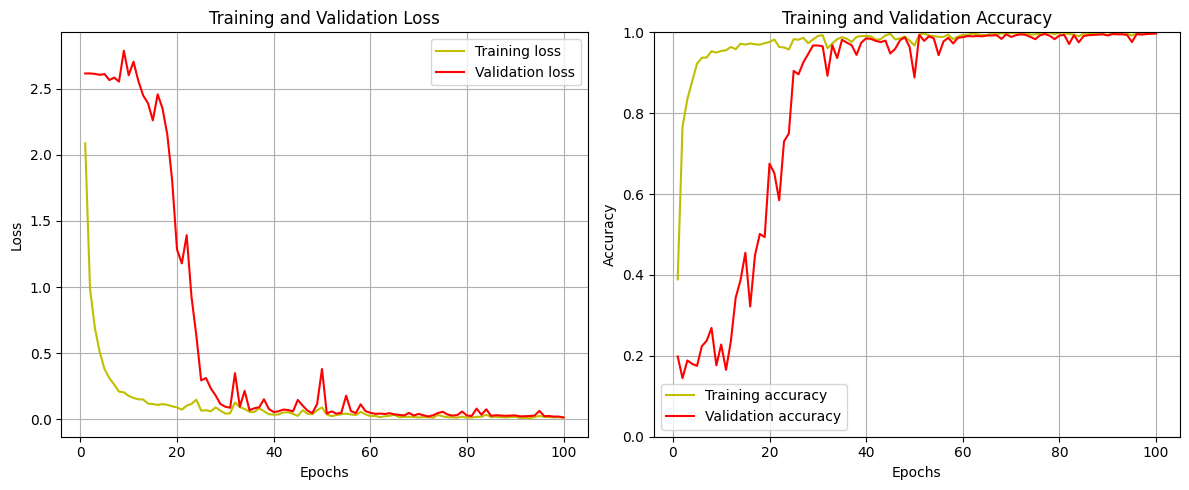

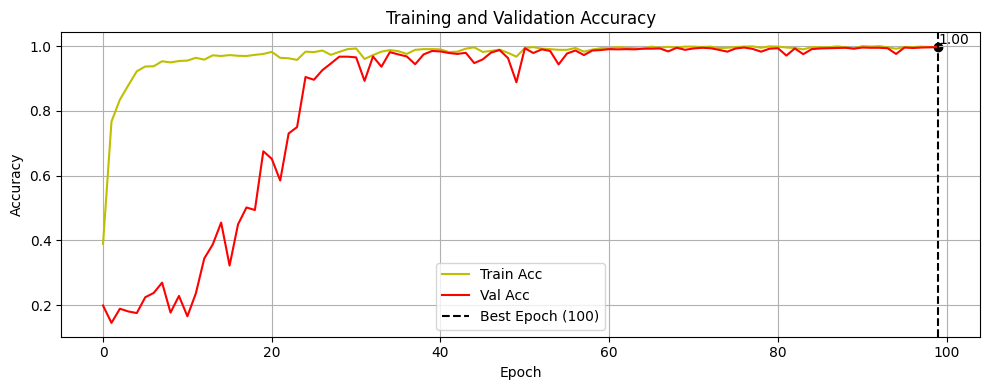

In [16]:
# ──────────────────────────────────────────────────────────────────────────
# Callbacks: save best weights + reduce learning rate on plateau.
# ──────────────────────────────────────────────────────────────────────────
checkpoint = ModelCheckpoint(
    CHECKPOINT_PATH,
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.5,
    patience=10,
    min_lr=5e-5
)

# ──────────────────────────────────────────────────────────────────────────
# Train the model.
# ──────────────────────────────────────────────────────────────────────────
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=[checkpoint, lr_callback],
)

# Plot training history
display_history(history)

---
## Cell 12 — Evaluation (OA, AA, Kappa)
Loads the best checkpoint, runs batched inference on the test set, and computes Overall Accuracy, Average Accuracy, and Cohen's Kappa.

Progress: 100%|██████████| 13/13 [00:04<00:00,  2.64it/s]


Overall Accuracy = 81.4
Average Accuracy = 84.88
Kappa            = 79.92

Per-class accuracy:
  Healthy Grass               82.05%
  Stressed Grass              83.18%
  Synthetic Grass             99.80%
  Tree                        91.38%
  Soil                       100.00%
  Water                       95.80%
  Residential                 86.10%
  Commercial                  66.57%
  Road                        82.53%
  Highway                     44.21%
  Railway                     64.99%
  Parking Lot1                86.36%
  Parking Lot2                90.18%
  Tennis Court               100.00%
  Running Track              100.00%


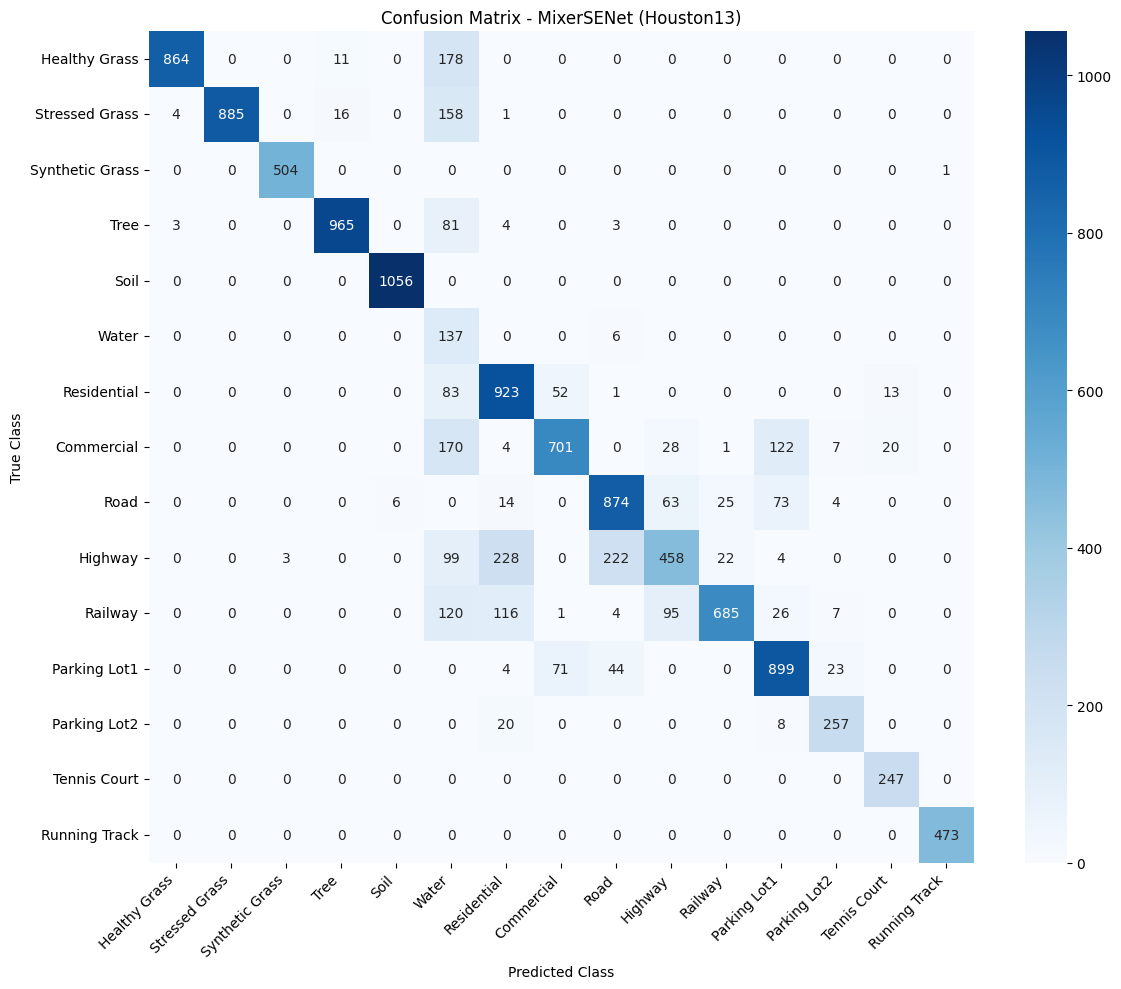

In [21]:
# ──────────────────────────────────────────────────────────────────────────
# Load the best weights and evaluate on the held-out test set.
# ──────────────────────────────────────────────────────────────────────────
model.load_weights(CHECKPOINT_PATH)

# Re-extract test labels (before one-hot) since y_test may have been
# overwritten during patching; reuse the original indices.
_, y_test_eval = get_img_indexes(Te_labels, removeZeroindexes=True)

Y_pred_test  = predict_by_batching(
    model, input_tensor_idx=X_test_idx,
    batch_size=1000, X=data, windowSize=WINDOW_SIZE
)
y_pred_test  = np.argmax(Y_pred_test, axis=1)

kappa     = cohen_kappa_score(y_test_eval, y_pred_test)
oa        = accuracy_score(y_test_eval, y_pred_test)
cm        = confusion_matrix(y_test_eval, y_pred_test)
class_acc = cm.diagonal() / cm.sum(axis=1)
aa        = np.mean(class_acc)

print("Overall Accuracy =", float(format(oa * 100, ".2f")))
print("Average Accuracy =", float(format(aa * 100, ".2f")))
print("Kappa            =", float(format(kappa * 100, ".2f")))
print("\nPer-class accuracy:")
for idx, (name, acc) in enumerate(zip(class_name, class_acc)):
    print(f"  {name:25s}  {acc*100:6.2f}%")

# ──────────────────────────────────────────────────────────────────────────
# Plot the Confusion Matrix
# ──────────────────────────────────────────────────────────────────────────
import seaborn as sns
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_name,
    yticklabels=class_name
)
plt.title("Confusion Matrix - MixerSENet (Houston13)")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## Cell 13 — Classification Map Generation & Visualisation
Generates the full predicted class map for the entire image and displays it alongside a masked version (only where ground truth is available).

Progress: 100%|██████████| 67/67 [04:15<00:00,  3.81s/it]


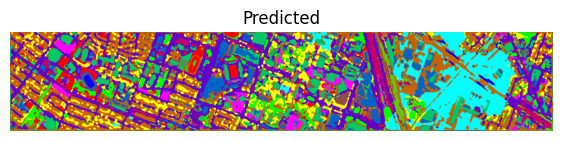

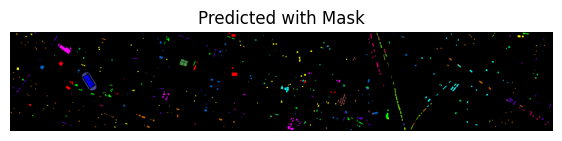

In [18]:
# ──────────────────────────────────────────────────────────────────────────
# Generate the full predicted class map and visualise.
# ──────────────────────────────────────────────────────────────────────────
model.load_weights(CHECKPOINT_PATH)

Predicted_Class_Map = get_class_map(model, data, gt, WINDOW_SIZE)
img_display(classes=Predicted_Class_Map, title='Predicted', class_name=class_name)

# Masked version — show predictions only where ground truth exists
gt_binary = gt.copy()
gt_binary[gt > 0] = 1
img_display(
    classes=Predicted_Class_Map * gt_binary,
    title='Predicted with Mask',
    class_name=class_name
)

---
## Cell 14 — Save Results to .mat File
Exports the predicted classification map as a MATLAB `.mat` file for external analysis.

In [19]:
# ──────────────────────────────────────────────────────────────────────────
# Save the predicted class map as a .mat file.
# ──────────────────────────────────────────────────────────────────────────
OUTPUT_FOLDER = 'Matlab_Outputs'
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

Name = 'Houston_MixerSENet'
sio.savemat(
    os.path.join(OUTPUT_FOLDER, Name + '.mat'),
    {Name: Predicted_Class_Map}
)

print(f'Saved: {os.path.join(OUTPUT_FOLDER, Name + ".mat")}')

Saved: Matlab_Outputs/Houston_MixerSENet.mat
